In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('student.csv',sep=';')
print(data.head(5))

       name  grade  study_hours  attendance  score
0    Karine      1          100           1      1
1   Aurthur      2           41           2      2
2   Rhiamon      3           40           3      3
3   Marcela      4           91           4      4
4  Brewster      5           19           5      5


In [3]:
print(f"Información del dataset:")
print(f"Dimensiones: {data.shape}")
print(f"Columnas: {list(data.columns)}")
print(data.columns.tolist())
data.columns = data.columns.str.strip()  # Eliminar espacios en blanco de los nombres de las columnas
print(f"Información general:")
print(data.info())

Información del dataset:
Dimensiones: (100, 5)
Columnas: ['name', 'grade', 'study_hours', 'attendance', 'score']
['name', 'grade', 'study_hours', 'attendance', 'score']
Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   name         100 non-null    object
 1   grade        100 non-null    int64 
 2   study_hours  100 non-null    int64 
 3   attendance   100 non-null    int64 
 4   score        100 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 4.0+ KB
None


In [4]:
# Calcular el promedio de puntajes
average_score = data['score'].mean()
print(f"Promedio de puntajes: {average_score:.2f}")

# Calcular la mediana de puntajes
median_score = data['score'].median()
print(f"Mediana de puntajes: {median_score:.2f}")

Promedio de puntajes: 50.50
Mediana de puntajes: 50.50


Encontrando el mayor y el menor de los puntajes de los estudiantes

In [5]:
mayor_puntaje = data['score'].max()
print(f"Mayor puntaje: {mayor_puntaje}")
menor_puntaje = data['score'].min()
print(f"Menor puntaje: {menor_puntaje}")

Mayor puntaje: 100
Menor puntaje: 1


Generdando un resumen estadistico con describe

In [6]:
print(f"Resumen estadístico:")
print(data.describe())

Resumen estadístico:
            grade  study_hours  attendance       score
count  100.000000   100.000000  100.000000  100.000000
mean    50.500000    49.270000   50.500000   50.500000
std     29.011492    26.368352   29.011492   29.011492
min      1.000000     1.000000    1.000000    1.000000
25%     25.750000    29.500000   25.750000   25.750000
50%     50.500000    49.000000   50.500000   50.500000
75%     75.250000    68.250000   75.250000   75.250000
max    100.000000   100.000000  100.000000  100.000000


In [7]:
print(data["score"].describe())

count    100.000000
mean      50.500000
std       29.011492
min        1.000000
25%       25.750000
50%       50.500000
75%       75.250000
max      100.000000
Name: score, dtype: float64


Filtrado de datos
Una de las funcionalidades más útiles de pandas es la capacidad de seleccionar filas basándose en condiciones.

Búsqueda de estudiantes con puntuaciones altas
Supongamos que queremos encontrar a los estudiantes que obtuvieron una puntuación de al menos 90:

In [8]:
high_scores = data[data["score"] >= 90]
print(high_scores)

          name  grade  study_hours  attendance  score
89      Tonnie     90           28          90     90
90     Lauritz     91           90          91     91
91  Ermentrude     92           75          92     92
92      Derron     93           49          93     93
93       Lucie     94           61          94     94
94        Gage     95           40          95     95
95    Mathilde     96           28          96     96
96      Clarie     97           54          97     97
97      Alicia     98           89          98     98
98    Morganne     99           72          99     99
99   Alejandro    100           15         100    100


In [9]:
data["score"] >= 90

0     False
1     False
2     False
3     False
4     False
      ...  
95     True
96     True
97     True
98     True
99     True
Name: score, Length: 100, dtype: bool

Cómo encontrar estudiantes que estudian más de cinco horas 
Podemos realizar la misma operación utilizando el tiempo de estudio:

In [10]:
frecuencia_De_estudios = data[data["study_hours"] > 5]
print(frecuencia_De_estudios)

         name  grade  study_hours  attendance  score
0      Karine      1          100           1      1
1     Aurthur      2           41           2      2
2     Rhiamon      3           40           3      3
3     Marcela      4           91           4      4
4    Brewster      5           19           5      5
..        ...    ...          ...         ...    ...
95   Mathilde     96           28          96     96
96     Clarie     97           54          97     97
97     Alicia     98           89          98     98
98   Morganne     99           72          99     99
99  Alejandro    100           15         100    100

[96 rows x 5 columns]


mutiples condiciones de horas de estudiantes

In [11]:
students = data[
    (data["study_hours"] > 5) &
    (data["attendance"] > 95)
]

print(students)

         name  grade  study_hours  attendance  score
95   Mathilde     96           28          96     96
96     Clarie     97           54          97     97
97     Alicia     98           89          98     98
98   Morganne     99           72          99     99
99  Alejandro    100           15         100    100


Cómo encontrar estudiantes específicos
Uso de idxmax()
A veces, no basta con obtener el valor más alto; también interesa saber qué registro lo contiene.

In [12]:
top_student_index = data["score"].idxmax()
top_student = data.loc[top_student_index]

print(top_student)

name           Alejandro
grade                100
study_hours           15
attendance           100
score                100
Name: 99, dtype: object


Lo mismo para las horas estudiadas

In [13]:
most_studious_index = data["study_hours"].idxmax()
most_studious_student = data.loc[most_studious_index]

print(most_studious_student)

name           Karine
grade               1
study_hours       100
attendance          1
score               1
Name: 0, dtype: object


Agrupación de datos
La agrupación resulta especialmente útil cuando el conjunto de datos contiene categorías.

En nuestro conjunto de datos, los estudiantes pertenecen a distintos grados.

Promedio de calificaciones por grado
Podemos calcular el promedio de calificaciones para cada grado:

In [14]:
average_by_grade = data.groupby("grade")["score"].mean()
print(average_by_grade)

grade
1        1.0
2        2.0
3        3.0
4        4.0
5        5.0
       ...  
96      96.0
97      97.0
98      98.0
99      99.0
100    100.0
Name: score, Length: 100, dtype: float64


In [15]:
average_by_grade = (
    data.groupby("grade")["score"]
    .mean()
    .round(2)
)

print(average_by_grade)

grade
1        1.0
2        2.0
3        3.0
4        4.0
5        5.0
       ...  
96      96.0
97      97.0
98      98.0
99      99.0
100    100.0
Name: score, Length: 100, dtype: float64


Estadísticas múltiples
Puedes calcular varias estadísticas a la vez:

In [16]:
grade_summary = data.groupby("grade")["score"].agg(
    ["mean", "min", "max", "count"]
)

print(grade_summary)

        mean  min  max  count
grade                        
1        1.0    1    1      1
2        2.0    2    2      1
3        3.0    3    3      1
4        4.0    4    4      1
5        5.0    5    5      1
...      ...  ...  ...    ...
96      96.0   96   96      1
97      97.0   97   97      1
98      98.0   98   98      1
99      99.0   99   99      1
100    100.0  100  100      1

[100 rows x 4 columns]


Análisis del tiempo de estudio
También podemos investigar la relación entre las horas de estudio y las calificaciones.

Cálculo de la correlación
Pandas ofrece un método `corr()`:

In [17]:
correlation = data["study_hours"].corr(data["score"])

print(f"Correlation: {correlation:.2f}")

Correlation: -0.07


El valor de correlación suele oscilar entre -1 y 1.

Un valor cercano a 1 indica una relación lineal positiva más fuerte, mientras que un valor cercano a -1 indica una relación lineal negativa más fuerte. Un valor próximo a 0 indica una escasa relación lineal.

Sin embargo, la correlación no demuestra que una variable sea la causa de otra. Por ejemplo, si en este conjunto de datos existe una correlación entre las horas de estudio y las calificaciones, esto no prueba que estudiar más haya provocado directamente la obtención de mejores calificaciones.

Creación de una visualización
Los números son útiles, pero las visualizaciones pueden facilitar el reconocimiento de patrones.

Creación de un diagrama de dispersión
Crearemos un diagrama de dispersión que muestre las horas de estudio y las calificaciones obtenidas en los exámenes:

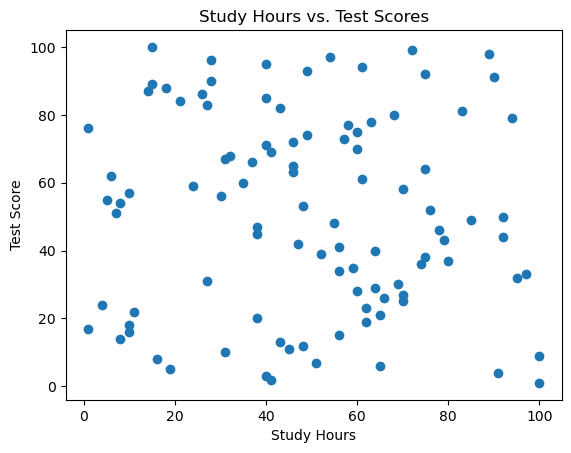

In [18]:
plt.scatter(data["study_hours"], data["score"])

plt.xlabel("Study Hours")
plt.ylabel("Test Score")
plt.title("Study Hours vs. Test Scores")

plt.show()

Creación de un gráfico de barras
También podemos visualizar la puntuación promedio para cada grado:

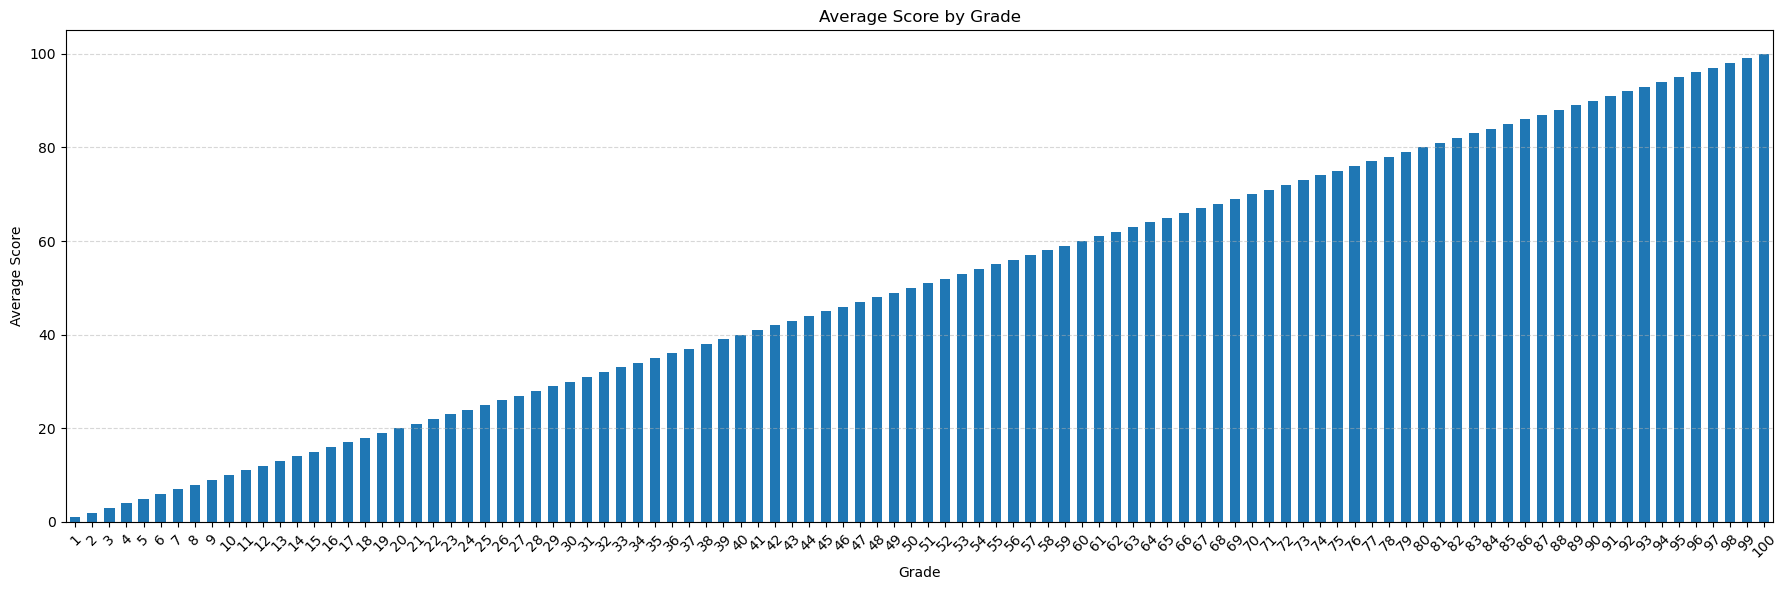

In [20]:
average_by_grade = data.groupby("grade")["score"].mean()

ax = average_by_grade.plot(
    kind="bar",
    figsize=(18, 6),
    width=0.6
)

ax.set_xlabel("Grade")
ax.set_ylabel("Average Score")
ax.set_title("Average Score by Grade")
ax.tick_params(axis="x", labelrotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Construcción del analizador completo
Ahora, combinemos las ideas principales en un único programa.

Dataset shape:
(100, 5)

First five rows:
       name  grade  study_hours  attendance  score
0    Karine      1          100           1      1
1   Aurthur      2           41           2      2
2   Rhiamon      3           40           3      3
3   Marcela      4           91           4      4
4  Brewster      5           19           5      5

Score Statistics
Average: 50.50
Median: 50.50
Highest: 100
Lowest: 1

Students with scores of 90 or higher:
          name  score
89      Tonnie     90
90     Lauritz     91
91  Ermentrude     92
92      Derron     93
93       Lucie     94
94        Gage     95
95    Mathilde     96
96      Clarie     97
97      Alicia     98
98    Morganne     99
99   Alejandro    100

Average Score by Grade:
grade
1        1.0
2        2.0
3        3.0
4        4.0
5        5.0
       ...  
96      96.0
97      97.0
98      98.0
99      99.0
100    100.0
Name: score, Length: 100, dtype: float64

Study Hours vs. Score Correlation: -0.07


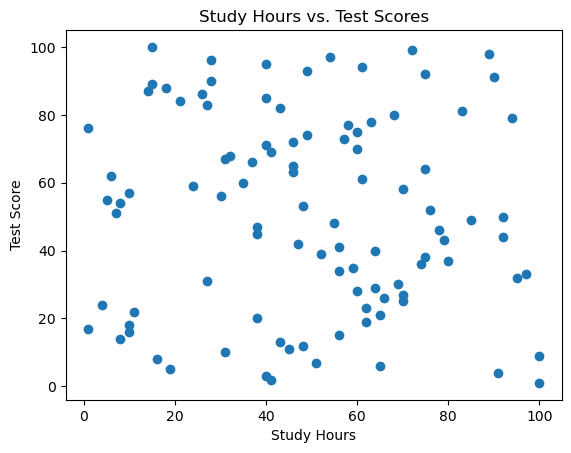

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("student.csv", sep=';')

# Basic information
print("Dataset shape:")
print(data.shape)

print("\nFirst five rows:")
print(data.head())

# Score statistics
average_score = data["score"].mean()
median_score = data["score"].median()
highest_score = data["score"].max()
lowest_score = data["score"].min()

print("\nScore Statistics")
print(f"Average: {average_score:.2f}")
print(f"Median: {median_score:.2f}")
print(f"Highest: {highest_score}")
print(f"Lowest: {lowest_score}")

# Students with scores of 90 or higher
high_scores = data[data["score"] >= 90]

print("\nStudents with scores of 90 or higher:")
print(high_scores[["name", "score"]])

# Average score by grade
average_by_grade = (
    data.groupby("grade")["score"]
    .mean()
    .round(2)
)

print("\nAverage Score by Grade:")
print(average_by_grade)

# Study hours and score correlation
correlation = data["study_hours"].corr(data["score"])

print(f"\nStudy Hours vs. Score Correlation: {correlation:.2f}")

# Scatter plot
plt.scatter(data["study_hours"], data["score"])

plt.xlabel("Study Hours")
plt.ylabel("Test Score")
plt.title("Study Hours vs. Test Scores")

plt.show()

Hacer que el analizador sea más reutilizable
Un siguiente paso útil consiste en convertir las operaciones repetidas en funciones.

Creación de una función de análisis
En lugar de escribirlo todo directamente en el programa principal, podemos crear una función:

In [24]:
def analyze_scores(data):
    average = data["score"].mean()
    median = data["score"].median()
    highest = data["score"].max()
    lowest = data["score"].min()

    print(f"Average score: {average:.2f}")
    print(f"Median score: {median:.2f}")
    print(f"Highest score: {highest}")
    print(f"Lowest score: {lowest}")

In [25]:
analyze_scores(data)

Average score: 50.50
Median score: 50.50
Highest score: 100
Lowest score: 1


Creación de una función para los estudiantes con mejores resultados
También podemos crear una función que devuelva a los estudiantes con las puntuaciones más altas:

In [26]:
def get_top_students(data, minimum_score=90):
    return data[data["score"] >= minimum_score][
        ["name", "grade", "score"]
    ]

Ahora podemos cambiar el umbral cuando queramos:

In [27]:
print(get_top_students(data,95))

         name  grade  score
94       Gage     95     95
95   Mathilde     96     96
96     Clarie     97     97
97     Alicia     98     98
98   Morganne     99     99
99  Alejandro    100    100


Gestión de datos faltantes

In [28]:
print(data.isnull().sum())

name           0
grade          0
study_hours    0
attendance     0
score          0
dtype: int64


Con estos valores sabemos cuantos valores faltantes tenemos en nuestro dataset, haora hay que quitarlos.

In [29]:
clean_data = data.dropna()

O bien, dependiendo del conjunto de datos y de lo que signifique el valor faltante, podrías reemplazar los valores faltantes:

In [30]:
data["score"] = data["score"].fillna(data["score"].mean())

No deberías reemplazar automáticamente cada valor faltante por un promedio. El enfoque adecuado depende de lo que representen los datos faltantes y de lo que intentes analizar.

Exportación de resultados
Tras analizar un conjunto de datos, es posible que desees guardar tus resultados.

In [31]:
average_by_grade.to_csv("average_scores_by_grade.csv")

In [32]:
high_scores.to_csv("high_scoring_students.csv", index=False)

El argumento index=False evita que pandas añada el índice del DataFrame como una columna adicional.